# Car Price Regression Modeling

This notebook trains and compares multiple regression models for `cleaned_data.csv` with `price_azn` as the target.

Main fixes and improvements:
- All preprocessing is inside sklearn pipelines, so train/test encodings stay aligned.
- Numeric features use median imputation plus RobustScaler.
- Low/medium-cardinality categorical features use OneHotEncoder.
- High-cardinality `ad` uses TargetEncoder when available, which is usually much stronger than label encoding for this dataset.
- The target is modeled as `log1p(price_azn)`, then predictions are converted back to AZN for MAE/RMSE/R2.
- Each model has its own cell so you can tune hyperparameters independently.
- Each trained pipeline is saved with joblib into `saved_models/`.

## 1. Imports and settings

In [1]:
import os
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count() or 1))
import re
import time
import glob
import joblib
import warnings

import numpy as np
import pandas as pd
import matplotlib
try:
    import matplotlib_inline
    matplotlib.use('module://matplotlib_inline.backend_inline')
except Exception:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt

from sklearn import metrics as sm
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
    StackingRegressor,
    VotingRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, LinearRegression, Ridge
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, RobustScaler

try:
    from sklearn.preprocessing import TargetEncoder
    HAS_TARGET_ENCODER = True
except Exception:
    TargetEncoder = None
    HAS_TARGET_ENCODER = False

try:
    from xgboost import XGBRegressor
except Exception:
    XGBRegressor = None

try:
    from lightgbm import LGBMRegressor
except Exception:
    LGBMRegressor = None

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 180)

RANDOM_STATE = 42
DATA_PATH = 'cleaned_data.csv'
TARGET = 'price_azn'
MODEL_DIR = 'saved_models'
os.makedirs(MODEL_DIR, exist_ok=True)

# Slow models use a fit sample by default so the notebook remains practical.
# Set any of these to None if you want to train that model on the full training set.
ELASTIC_NET_FIT_ROWS = 30_000
BAGGING_FIT_ROWS = None
GRADIENT_BOOSTING_FIT_ROWS = 60_000
ENSEMBLE_FIT_ROWS = None

print('TargetEncoder available:', HAS_TARGET_ENCODER)
print('XGBoost available:', XGBRegressor is not None)
print('LightGBM available:', LGBMRegressor is not None)


TargetEncoder available: True
XGBoost available: True
LightGBM available: True


## 2. Load data

In [2]:
raw_df = pd.read_csv(DATA_PATH)
print('Shape:', raw_df.shape)
display(raw_df.head())
raw_df.info()


Shape: (223758, 17)


,ad,motor,probeg,Ban növü,Hansı bazar üçün yığılıb,Rəng,Sahiblər,Sürətlər qutusu,Vəziyyəti,Yeni,Yerlərin sayı,Ötürücü,Şəhər,yas,at_gucu,Yanacaq,price_azn
0,Hyundai i30,1.6,270000,"Hetçbek, 5 qapı",Avropa,Gümüşü,2.0,Mexaniki,"Vuruğu yoxdur, rənglənməyib",Xeyr,5.0,Ön,Bakı,18,115.0,Dizel,15000.0
1,LADA (VAZ) Niva Travel,1.7,0,"Offroader / SUV, 5 qapı",Rəsmi diler,Yaşıl,1.0,Mexaniki,"Vuruğu yoxdur, rənglənməyib",Bəli,5.0,Tam,Bakı,2,80.0,Benzin,23700.0
2,Toyota Land Cruiser,4.0,164750,"Offroader / SUV, 5 qapı",Rəsmi diler,Ağ,0.0,Avtomat,"Vuruğu yoxdur, rənglənməyib",Xeyr,8.0,Tam,Bakı,15,282.0,Benzin,60520.0
3,Hyundai Elantra,2.0,126000,Sedan,Avropa,Boz,1.0,Avtomat,"Vuruğu yoxdur, rənglənməyib",Xeyr,5.0,Ön,Bakı,8,150.0,Benzin,26700.0
4,Toyota Prius,1.5,354000,Liftbek,Amerika,Qırmızı,2.0,Variator,"Vuruğu yoxdur, rənglənməyib",Xeyr,5.0,Ön,Bakı,19,76.0,Hibrid,10500.0


<class 'pandas.DataFrame'>
RangeIndex: 223758 entries, 0 to 223757
Data columns (total 17 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ad                        223758 non-null  str    
 1   motor                     223758 non-null  float64
 2   probeg                    223758 non-null  int64  
 3   Ban növü                  223758 non-null  str    
 4   Hansı bazar üçün yığılıb  223758 non-null  str    
 5   Rəng                      223758 non-null  str    
 6   Sahiblər                  223758 non-null  float64
 7   Sürətlər qutusu           223758 non-null  str    
 8   Vəziyyəti                 223758 non-null  str    
 9   Yeni                      223758 non-null  str    
 10  Yerlərin sayı             223758 non-null  float64
 11  Ötürücü                   223758 non-null  str    
 12  Şəhər                     223758 non-null  str    
 13  yas                       223758 non-null  int64  
 14 

## 3. Quick data audit

In [3]:
audit = pd.DataFrame({
    'dtype': raw_df.dtypes.astype(str),
    'missing': raw_df.isna().sum(),
    'nunique': raw_df.nunique(dropna=False),
})
display(audit)

display(raw_df[TARGET].describe().to_frame())


,dtype,missing,nunique
ad,str,0,2529
motor,float64,0,88
probeg,int64,0,33530
Ban növü,str,0,36
Hansı bazar üçün yığılıb,str,0,9
Rəng,str,0,18
Sahiblər,float64,0,5
Sürətlər qutusu,str,0,5
Vəziyyəti,str,0,4
Yeni,str,0,2


,price_azn
count,223758.000000
mean,28944.798274
std,34318.735031
min,500.000000
25%,11900.000000
50%,20800.000000
75%,33500.000000
max,940000.000000


## 4. Feature engineering

In [4]:
def add_features(data):
    data = data.copy()

    # Mileage is very right-skewed, so log mileage is easier for models to use.
    data['probeg_log'] = np.log1p(data['probeg'].clip(lower=0))

    # Normalize mileage by age. Add 1 so new cars do not divide by zero.
    data['km_per_year'] = data['probeg'] / (data['yas'].clip(lower=0) + 1)

    # Engine efficiency / intensity style ratios.
    data['power_per_liter'] = data['at_gucu'] / data['motor'].replace(0, np.nan)
    data['age_power'] = data['yas'] * data['at_gucu']

    # Useful for new or nearly-new cars.
    data['is_zero_probeg'] = (data['probeg'] == 0).astype(int)

    # Brand is the first token in the ad name. Keep full ad separately for target encoding.
    data['brand'] = data['ad'].astype(str).str.split().str[0].fillna('Unknown')

    data = data.replace([np.inf, -np.inf], np.nan)
    return data

model_df = add_features(raw_df)
RAW_FEATURE_COLUMNS = [c for c in raw_df.columns if c != TARGET]

X = model_df.drop(columns=[TARGET])
y = np.log1p(model_df[TARGET])
MODEL_FEATURE_COLUMNS = X.columns.tolist()

print('Model matrix shape:', X.shape)
display(X.head())


Model matrix shape: (223758, 22)


,ad,motor,probeg,Ban növü,Hansı bazar üçün yığılıb,Rəng,Sahiblər,Sürətlər qutusu,Vəziyyəti,Yeni,Yerlərin sayı,Ötürücü,Şəhər,yas,at_gucu,Yanacaq,probeg_log,km_per_year,power_per_liter,age_power,is_zero_probeg,brand
0,Hyundai i30,1.6,270000,"Hetçbek, 5 qapı",Avropa,Gümüşü,2.0,Mexaniki,"Vuruğu yoxdur, rənglənməyib",Xeyr,5.0,Ön,Bakı,18,115.0,Dizel,12.506181,14210.526316,71.875000,2070.0,0,Hyundai
1,LADA (VAZ) Niva Travel,1.7,0,"Offroader / SUV, 5 qapı",Rəsmi diler,Yaşıl,1.0,Mexaniki,"Vuruğu yoxdur, rənglənməyib",Bəli,5.0,Tam,Bakı,2,80.0,Benzin,0.000000,0.000000,47.058824,160.0,1,LADA
2,Toyota Land Cruiser,4.0,164750,"Offroader / SUV, 5 qapı",Rəsmi diler,Ağ,0.0,Avtomat,"Vuruğu yoxdur, rənglənməyib",Xeyr,8.0,Tam,Bakı,15,282.0,Benzin,12.012191,10296.875000,70.500000,4230.0,0,Toyota
3,Hyundai Elantra,2.0,126000,Sedan,Avropa,Boz,1.0,Avtomat,"Vuruğu yoxdur, rənglənməyib",Xeyr,5.0,Ön,Bakı,8,150.0,Benzin,11.744045,14000.000000,75.000000,1200.0,0,Hyundai
4,Toyota Prius,1.5,354000,Liftbek,Amerika,Qırmızı,2.0,Variator,"Vuruğu yoxdur, rənglənməyib",Xeyr,5.0,Ön,Bakı,19,76.0,Hibrid,12.777055,17700.000000,50.666667,1444.0,0,Toyota


## 5. Feature groups

In [5]:
numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

# High-cardinality categorical feature: target encoding is stronger and smaller than one-hot here.
high_card_features = ['ad'] if 'ad' in categorical_features else []
ohe_features = [c for c in categorical_features if c not in high_card_features]

print('Numeric features:', numeric_features)
print('One-hot categorical features:', ohe_features)
print('High-cardinality encoded features:', high_card_features)


Numeric features: ['motor', 'probeg', 'Sahiblər', 'Yerlərin sayı', 'yas', 'at_gucu', 'probeg_log', 'km_per_year', 'power_per_liter', 'age_power', 'is_zero_probeg']
One-hot categorical features: ['Ban növü', 'Hansı bazar üçün yığılıb', 'Rəng', 'Sürətlər qutusu', 'Vəziyyəti', 'Yeni', 'Ötürücü', 'Şəhər', 'Yanacaq', 'brand']
High-cardinality encoded features: ['ad']


## 6. Train / test split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

Y_LOG_MIN = float(y_train.min())
Y_LOG_MAX = float(y_train.max())

print('Train:', X_train.shape)
print('Test :', X_test.shape)
print('Log target range:', (Y_LOG_MIN, Y_LOG_MAX))


Train: (179006, 22)
Test : (44752, 22)
Log target range: (6.2166061010848646, 13.753636218075409)


## 7. Shared preprocessor

In [7]:
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
])

ohe_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=20,
        sparse_output=False,
    )),
])

if HAS_TARGET_ENCODER and high_card_features:
    high_card_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('target', TargetEncoder(
            target_type='continuous',
            smooth='auto',
            cv=5,
            random_state=RANDOM_STATE,
        )),
    ])
else:
    high_card_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ])

transformers = [
    ('num', numeric_pipe, numeric_features),
    ('ohe', ohe_pipe, ohe_features),
]
if high_card_features:
    transformers.append(('high_card', high_card_pipe, high_card_features))

BASE_PREPROCESSOR = ColumnTransformer(
    transformers=transformers,
    remainder='drop',
    verbose_feature_names_out=False,
)

print('Preprocessor ready. It will be cloned separately for each model.')


Preprocessor ready. It will be cloned separately for each model.


## 8. Scoring, saving, and prediction helpers

In [8]:
comparison_results = {}
model_files = {}
trained_models = {}


def slugify(name):
    return re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_')


def clip_log_predictions(y_pred_log):
    return np.clip(np.asarray(y_pred_log, dtype=float), Y_LOG_MIN, Y_LOG_MAX)


def regression_metrics(y_true_log, y_pred_log):
    y_pred_log = clip_log_predictions(y_pred_log)
    y_true_azn = np.expm1(y_true_log)
    y_pred_azn = np.expm1(y_pred_log)

    return {
        'R2 log': sm.r2_score(y_true_log, y_pred_log),
        'R2 AZN': sm.r2_score(y_true_azn, y_pred_azn),
        'MAE AZN': sm.mean_absolute_error(y_true_azn, y_pred_azn),
        'RMSE AZN': sm.root_mean_squared_error(y_true_azn, y_pred_azn),
        'RMSE log': sm.root_mean_squared_error(y_true_log, y_pred_log),
    }


def sample_fit_data(fit_rows=None):
    if fit_rows is None or fit_rows >= len(X_train):
        return X_train, y_train

    sample_index = X_train.sample(n=fit_rows, random_state=RANDOM_STATE).index
    return X_train.loc[sample_index], y_train.loc[sample_index]


def fit_evaluate_save(model_name, estimator, fit_rows=None):
    if estimator is None:
        comparison_results[model_name] = {'Status': 'Skipped'}
        print(f'{model_name}: skipped because the package is not installed.')
        return None

    X_fit, y_fit = sample_fit_data(fit_rows)
    pipe = Pipeline([
        ('prep', clone(BASE_PREPROCESSOR)),
        ('model', estimator),
    ])

    start = time.time()
    pipe.fit(X_fit, y_fit)
    seconds = time.time() - start

    train_pred = pipe.predict(X_fit)
    test_pred = pipe.predict(X_test)

    train_scores = regression_metrics(y_fit, train_pred)
    test_scores = regression_metrics(y_test, test_pred)

    comparison_results[model_name] = {
        'Status': 'OK',
        'Fit rows': len(X_fit),
        'Train R2 log': train_scores['R2 log'],
        'Test R2 log': test_scores['R2 log'],
        'Gap R2 log': train_scores['R2 log'] - test_scores['R2 log'],
        'Train R2 AZN': train_scores['R2 AZN'],
        'Test R2 AZN': test_scores['R2 AZN'],
        'Test MAE AZN': test_scores['MAE AZN'],
        'Test RMSE AZN': test_scores['RMSE AZN'],
        'Train RMSE log': train_scores['RMSE log'],
        'Test RMSE log': test_scores['RMSE log'],
        'Seconds': seconds,
    }

    file_path = os.path.join(MODEL_DIR, f'{slugify(model_name)}.pkl')
    joblib.dump(pipe, file_path)
    model_files[model_name] = file_path
    trained_models[model_name] = pipe

    score_table = pd.DataFrame([train_scores, test_scores], index=['Train', 'Test'])
    print(f'{model_name} saved to {file_path}')
    print(f'Trained on {len(X_fit):,} rows in {seconds:.1f} seconds')
    display(score_table)
    return pipe


def make_model_input(user_input):
    input_df = pd.DataFrame([user_input]).copy()

    for col in RAW_FEATURE_COLUMNS:
        if col not in input_df.columns:
            input_df[col] = np.nan

    input_df = input_df[RAW_FEATURE_COLUMNS]
    input_df = add_features(input_df)
    return input_df[MODEL_FEATURE_COLUMNS]


def predict_price(user_input, model_name):
    if model_name in trained_models:
        pipe = trained_models[model_name]
    else:
        file_path = os.path.join(MODEL_DIR, f'{slugify(model_name)}.pkl')
        pipe = joblib.load(file_path)

    model_input = make_model_input(user_input)
    pred_log = pipe.predict(model_input)[0]
    pred_azn = np.expm1(clip_log_predictions([pred_log]))[0]
    return float(pred_azn)


def predict_all_models(user_input):
    rows = []
    pkl_files = sorted(glob.glob(os.path.join(MODEL_DIR, '*.pkl')))

    for file_path in pkl_files:
        model_name = os.path.splitext(os.path.basename(file_path))[0]
        pipe = joblib.load(file_path)
        pred_log = pipe.predict(make_model_input(user_input))[0]
        pred_azn = np.expm1(clip_log_predictions([pred_log]))[0]
        rows.append({'model_file': os.path.basename(file_path), 'predicted_price_azn': pred_azn})

    return pd.DataFrame(rows).sort_values('predicted_price_azn')


## 9. Linear Regression

In [9]:
linear_regression_pipe = fit_evaluate_save(
    'Linear Regression',
    LinearRegression(),
)


Linear Regression saved to saved_models/linear_regression.pkl
Trained on 179,006 rows in 1.8 seconds


,R2 log,R2 AZN,MAE AZN,RMSE AZN,RMSE log
Train,0.882546,0.755173,5927.639056,17049.648203,0.282498
Test,0.880037,0.739785,5929.089714,17219.643259,0.285598


## 10. Ridge Regression

In [10]:
ridge_pipe = fit_evaluate_save(
    'Ridge',
    Ridge(alpha=1.0, random_state=RANDOM_STATE),
    # Tune alpha: 0.1, 1, 10, 100
)


Ridge saved to saved_models/ridge.pkl
Trained on 179,006 rows in 0.8 seconds


,R2 log,R2 AZN,MAE AZN,RMSE AZN,RMSE log
Train,0.882571,0.755275,5927.835521,17046.107501,0.282468
Test,0.880033,0.739845,5929.919745,17217.650552,0.285603


## 11. Elastic Net

In [11]:
elastic_net_pipe = fit_evaluate_save(
    'Elastic Net',
    ElasticNet(
        alpha=0.0005,
        l1_ratio=0.15,
        max_iter=2000,
        tol=1e-3,
        selection='random',
        random_state=RANDOM_STATE,
    ),
    fit_rows=ELASTIC_NET_FIT_ROWS,
    # Tune alpha: 0.0001, 0.0005, 0.001
    # Tune l1_ratio: 0.05, 0.15, 0.5
)


Elastic Net saved to saved_models/elastic_net.pkl
Trained on 30,000 rows in 1.4 seconds


,R2 log,R2 AZN,MAE AZN,RMSE AZN,RMSE log
Train,0.879676,0.733631,6002.678396,17466.934628,0.284195
Test,0.865466,0.716660,6311.204090,17968.508812,0.302446


## 12. Random Forest

In [12]:
random_forest_pipe = fit_evaluate_save(
    'Random Forest',
    RandomForestRegressor(
        n_estimators=150,
        max_features=0.50,
        min_samples_leaf=2,
        bootstrap=True,
        max_samples=0.80,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    fit_rows=BAGGING_FIT_ROWS,
    # Increase n_estimators to 150-300 and set fit_rows=None for a slower full run.
)


Random Forest saved to saved_models/random_forest.pkl
Trained on 179,006 rows in 20.6 seconds


,R2 log,R2 AZN,MAE AZN,RMSE AZN,RMSE log
Train,0.983730,0.968309,1598.260606,6134.131343,0.105142
Test,0.962028,0.954837,2367.882662,7173.826884,0.160680


## 13. Extra Trees

In [13]:
extra_trees_pipe = fit_evaluate_save(
    'Extra Trees',
    ExtraTreesRegressor(
        n_estimators=80,
        max_features=1.0,
        min_samples_leaf=2,
        bootstrap=True,
        max_samples=0.80,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    fit_rows=BAGGING_FIT_ROWS,
    # Increase n_estimators to 150-300 and set fit_rows=None for a slower full run.
)


Extra Trees saved to saved_models/extra_trees.pkl
Trained on 179,006 rows in 20.7 seconds


,R2 log,R2 AZN,MAE AZN,RMSE AZN,RMSE log
Train,0.983090,0.966163,1659.273743,6338.442826,0.107189
Test,0.961601,0.953359,2401.971765,7290.203578,0.161582


## 14. Gradient Boosting

In [14]:
gradient_boosting_pipe = fit_evaluate_save(
    'Gradient Boosting',
    GradientBoostingRegressor(
        n_estimators=120,
        learning_rate=0.06,
        max_depth=3,
        subsample=0.75,
        min_samples_leaf=10,
        random_state=RANDOM_STATE,
    ),
    fit_rows=GRADIENT_BOOSTING_FIT_ROWS,
    # Tune n_estimators: 100, 150, 250
    # Tune learning_rate: 0.03, 0.05, 0.08
)


Gradient Boosting saved to saved_models/gradient_boosting.pkl
Trained on 60,000 rows in 13.1 seconds


,R2 log,R2 AZN,MAE AZN,RMSE AZN,RMSE log
Train,0.922993,0.861444,4795.915471,12759.709473,0.228109
Test,0.914499,0.851077,4937.405832,13026.813290,0.241112


## 15. HistGradientBoosting

In [15]:
hist_gradient_boosting_pipe = fit_evaluate_save(
    'Hist Gradient Boosting',
    HistGradientBoostingRegressor(
        max_iter=350,
        learning_rate=0.06,
        max_leaf_nodes=63,
        l2_regularization=0.05,
        random_state=RANDOM_STATE,
    ),
    # Tune max_iter: 250, 350, 500
    # Tune max_leaf_nodes: 31, 63, 127
)


Hist Gradient Boosting saved to saved_models/hist_gradient_boosting.pkl
Trained on 179,006 rows in 17.2 seconds


,R2 log,R2 AZN,MAE AZN,RMSE AZN,RMSE log
Train,0.962655,0.945126,2913.293797,8071.805687,0.159293
Test,0.954906,0.940212,3069.811686,8253.977420,0.175102


## 16. XGBoost

In [16]:
xgboost_pipe = fit_evaluate_save(
    'XGBoost',
    None if XGBRegressor is None else XGBRegressor(
        n_estimators=700,
        learning_rate=0.045,
        max_depth=7,
        min_child_weight=4,
        subsample=0.90,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=0.70,
        objective='reg:squarederror',
        tree_method='hist',
        n_jobs=-1,
        random_state=RANDOM_STATE,
        verbosity=0,
    ),
    # Tune n_estimators: 500, 700, 1000
    # Tune max_depth: 5, 6, 7, 8
    # Tune learning_rate: 0.03, 0.045, 0.06
)


XGBoost saved to saved_models/xgboost.pkl
Trained on 179,006 rows in 6.3 seconds


,R2 log,R2 AZN,MAE AZN,RMSE AZN,RMSE log
Train,0.964428,0.950144,2880.505674,7693.831306,0.155466
Test,0.955537,0.943627,3063.703276,8014.835527,0.173873


## 17. LightGBM

In [17]:
lightgbm_pipe = fit_evaluate_save(
    'LightGBM',
    None if LGBMRegressor is None else LGBMRegressor(
        n_estimators=700,
        learning_rate=0.045,
        num_leaves=63,
        min_child_samples=30,
        subsample=0.90,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=0.30,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        verbose=-1,
    ),
    # Tune n_estimators: 500, 700, 1000
    # Tune num_leaves: 31, 63, 127
    # Tune learning_rate: 0.03, 0.045, 0.06
)


LightGBM saved to saved_models/lightgbm.pkl
Trained on 179,006 rows in 3.3 seconds


,R2 log,R2 AZN,MAE AZN,RMSE AZN,RMSE log
Train,0.965546,0.952166,2757.199299,7536.228782,0.153002
Test,0.956995,0.944697,2959.231494,7938.417537,0.170998


## 18. Voting Regressor

In [18]:
voting_estimators = []

if LGBMRegressor is not None:
    voting_estimators.append(('lgbm', LGBMRegressor(
        n_estimators=350,
        learning_rate=0.05,
        num_leaves=63,
        min_child_samples=30,
        subsample=0.90,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=0.30,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        verbose=-1,
    )))

if XGBRegressor is not None:
    voting_estimators.append(('xgb', XGBRegressor(
        n_estimators=350,
        learning_rate=0.05,
        max_depth=7,
        min_child_weight=4,
        subsample=0.90,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=0.70,
        objective='reg:squarederror',
        tree_method='hist',
        n_jobs=-1,
        random_state=RANDOM_STATE,
        verbosity=0,
    )))

voting_estimators.append(('hgb', HistGradientBoostingRegressor(
    max_iter=250,
    learning_rate=0.06,
    max_leaf_nodes=63,
    l2_regularization=0.05,
    random_state=RANDOM_STATE,
)))

voting_pipe = fit_evaluate_save(
    'Voting',
    VotingRegressor(voting_estimators, n_jobs=1) if len(voting_estimators) >= 2 else None,
    fit_rows=ENSEMBLE_FIT_ROWS,
)


Voting saved to saved_models/voting.pkl
Trained on 179,006 rows in 17.5 seconds


,R2 log,R2 AZN,MAE AZN,RMSE AZN,RMSE log
Train,0.961375,0.943675,2987.423472,8177.824603,0.161999
Test,0.954459,0.938921,3122.621274,8342.636170,0.175969


## 19. Stacking Regressor

In [19]:
stacking_estimators = []

if LGBMRegressor is not None:
    stacking_estimators.append(('lgbm', LGBMRegressor(
        n_estimators=250,
        learning_rate=0.05,
        num_leaves=63,
        min_child_samples=30,
        subsample=0.90,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=0.30,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        verbose=-1,
    )))

if XGBRegressor is not None:
    stacking_estimators.append(('xgb', XGBRegressor(
        n_estimators=250,
        learning_rate=0.05,
        max_depth=7,
        min_child_weight=4,
        subsample=0.90,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=0.70,
        objective='reg:squarederror',
        tree_method='hist',
        n_jobs=-1,
        random_state=RANDOM_STATE,
        verbosity=0,
    )))

stacking_estimators.append(('hgb', HistGradientBoostingRegressor(
    max_iter=180,
    learning_rate=0.06,
    max_leaf_nodes=63,
    l2_regularization=0.05,
    random_state=RANDOM_STATE,
)))

stacking_pipe = fit_evaluate_save(
    'Stacking',
    StackingRegressor(
        estimators=stacking_estimators,
        final_estimator=Ridge(alpha=5.0),
        cv=3,
        passthrough=False,
        n_jobs=1,
    ) if len(stacking_estimators) >= 2 else None,
    fit_rows=ENSEMBLE_FIT_ROWS,
)


Stacking saved to saved_models/stacking.pkl
Trained on 179,006 rows in 49.6 seconds


,R2 log,R2 AZN,MAE AZN,RMSE AZN,RMSE log
Train,0.959314,0.941099,3074.165638,8362.678206,0.166266
Test,0.953304,0.936371,3196.457093,8514.989743,0.178185


## 20. Compare all model scores

In [20]:
results_df = pd.DataFrame(comparison_results).T

if 'Status' in results_df.columns:
    results_df = results_df[results_df['Status'].eq('OK')].drop(columns=['Status'])

numeric_cols = results_df.columns.drop('Fit rows', errors='ignore')
results_df[numeric_cols] = results_df[numeric_cols].apply(pd.to_numeric, errors='coerce')
results_df = results_df.sort_values('Test R2 log', ascending=False)

comparison_path = os.path.join(MODEL_DIR, 'model_comparison.csv')
results_df.to_csv(comparison_path)
print('Saved comparison to:', comparison_path)
display(results_df)

best_model_name = results_df.index[0]
print('Best model by Test R2 log:', best_model_name)
print('Saved model file:', model_files.get(best_model_name, os.path.join(MODEL_DIR, f'{slugify(best_model_name)}.pkl')))


Saved comparison to: saved_models/model_comparison.csv


,Fit rows,Train R2 log,Test R2 log,Gap R2 log,Train R2 AZN,Test R2 AZN,Test MAE AZN,Test RMSE AZN,Train RMSE log,Test RMSE log,Seconds
Random Forest,179006,0.983730,0.962028,0.021702,0.968309,0.954837,2367.882662,7173.826884,0.105142,0.160680,20.560533
Extra Trees,179006,0.983090,0.961601,0.021489,0.966163,0.953359,2401.971765,7290.203578,0.107189,0.161582,20.696897
LightGBM,179006,0.965546,0.956995,0.008551,0.952166,0.944697,2959.231494,7938.417537,0.153002,0.170998,3.331840
XGBoost,179006,0.964428,0.955537,0.008892,0.950144,0.943627,3063.703276,8014.835527,0.155466,0.173873,6.328768
Hist Gradient Boosting,179006,0.962655,0.954906,0.007749,0.945126,0.940212,3069.811686,8253.977420,0.159293,0.175102,17.227793
Voting,179006,0.961375,0.954459,0.006917,0.943675,0.938921,3122.621274,8342.636170,0.161999,0.175969,17.464158
Stacking,179006,0.959314,0.953304,0.006010,0.941099,0.936371,3196.457093,8514.989743,0.166266,0.178185,49.614260
Gradient Boosting,60000,0.922993,0.914499,0.008494,0.861444,0.851077,4937.405832,13026.813290,0.228109,0.241112,13.064053
Linear Regression,179006,0.882546,0.880037,0.002509,0.755173,0.739785,5929.089714,17219.643259,0.282498,0.285598,1.764421
Ridge,179006,0.882571,0.880033,0.002538,0.755275,0.739845,5929.919745,17217.650552,0.282468,0.285603,0.812098


Best model by Test R2 log: Random Forest
Saved model file: saved_models/random_forest.pkl


## 21. Comparison plot

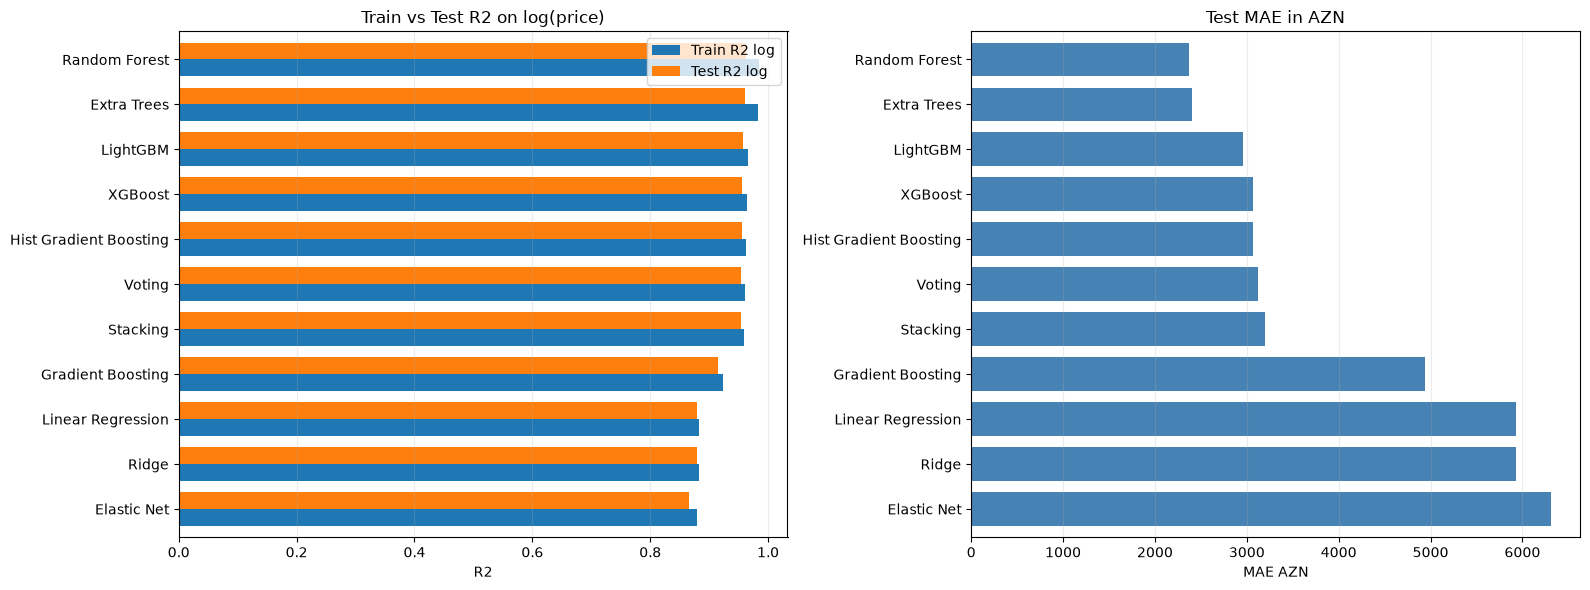

In [21]:
plot_df = results_df.copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_df[['Train R2 log', 'Test R2 log']].sort_values('Test R2 log').plot(
    kind='barh', ax=axes[0], width=0.75
)
axes[0].set_title('Train vs Test R2 on log(price)')
axes[0].set_xlabel('R2')
axes[0].grid(axis='x', alpha=0.25)

plot_df['Test MAE AZN'].sort_values(ascending=False).plot(
    kind='barh', ax=axes[1], color='steelblue', width=0.75
)
axes[1].set_title('Test MAE in AZN')
axes[1].set_xlabel('MAE AZN')
axes[1].grid(axis='x', alpha=0.25)

plt.tight_layout()
plt.show()


## 22. List saved models

In [22]:
saved_model_files = sorted(glob.glob(os.path.join(MODEL_DIR, '*.pkl')))
print(f'Saved {len(saved_model_files)} model files:')
for file_path in saved_model_files:
    print('-', file_path)


Saved 11 model files:
- saved_models/elastic_net.pkl
- saved_models/extra_trees.pkl
- saved_models/gradient_boosting.pkl
- saved_models/hist_gradient_boosting.pkl
- saved_models/lightgbm.pkl
- saved_models/linear_regression.pkl
- saved_models/random_forest.pkl
- saved_models/ridge.pkl
- saved_models/stacking.pkl
- saved_models/voting.pkl
- saved_models/xgboost.pkl


## 23. User input for prediction

In [23]:
# Start from a real row so every required field is present, then edit values as needed.
example_user_input = raw_df[RAW_FEATURE_COLUMNS].iloc[0].to_dict()
example_user_input


{'ad': 'Hyundai i30',
 'motor': 1.6,
 'probeg': 270000,
 'Ban növü': 'Hetçbek, 5 qapı',
 'Hansı bazar üçün yığılıb': 'Avropa',
 'Rəng': 'Gümüşü',
 'Sahiblər': 2.0,
 'Sürətlər qutusu': 'Mexaniki',
 'Vəziyyəti': 'Vuruğu yoxdur, rənglənməyib',
 'Yeni': 'Xeyr',
 'Yerlərin sayı': 5.0,
 'Ötürücü': 'Ön',
 'Şəhər': 'Bakı',
 'yas': 18,
 'at_gucu': 115.0,
 'Yanacaq': 'Dizel'}

In [24]:
exp = {'ad': 'Daewoo Nexia',
 'motor': 1.5,
 'probeg': 732000,
 'Ban növü': 'Sedan',
 'Hansı bazar üçün yığılıb': 'Avropa',
 'Rəng': 'Gümüşü',
 'Sahiblər': 2.0,
 'Sürətlər qutusu': 'Mexaniki',
 'Vəziyyəti': 'Vuruğu yoxdur, rənglənməyib',
 'Yeni': 'Xeyr',
 'Yerlərin sayı': 5.0,
 'Ötürücü': 'Ön',
 'Şəhər': 'Bakı',
 'yas': 28,
 'at_gucu': 80.0,
 'Yanacaq': 'Dizel'}

## 24. Predict with every saved model

In [25]:
all_predictions = predict_all_models(exp)
display(all_predictions)


,model_file,predicted_price_azn
0,elastic_net.pkl,2669.929074
5,linear_regression.pkl,2926.744740
7,ridge.pkl,2928.128774
6,random_forest.pkl,3476.254959
3,hist_gradient_boosting.pkl,3600.271117
4,lightgbm.pkl,3735.347900
9,voting.pkl,3854.354322
8,stacking.pkl,3917.956623
10,xgboost.pkl,3993.745293
1,extra_trees.pkl,4476.094834


## 25. Predict with one selected model

In [26]:
# Use any saved model name from the comparison table, for example:
# 'LightGBM', 'XGBoost', 'Hist Gradient Boosting', 'Random Forest', 'Ridge'
CHOSEN_MODEL = 'elastic_net'

predicted_price = predict_price(example_user_input, CHOSEN_MODEL)
print(f'{CHOSEN_MODEL} predicted price: {predicted_price:,.2f} AZN')


elastic_net predicted price: 12,576.36 AZN
